# Sanity check 1: our ESM-C gets good pseudo-log-likelihoods

Checks that `mutant_cache.backbone.load_esmc` is a working protein LM, not merely one that matches the official model on two hand-picked sequences:

1. **Parity with the official model on PLL.** Per-residue masked log-probs from our ESM-C 300M vs `esm.models.esmc.ESMC.from_pretrained("esmc_300m")`. The official model has its own loader and tokenizer, so no code is shared with ours.
2. **The numbers are good.** Natural proteins should have a much lower pseudo-perplexity than shuffled versions of themselves (same composition) and uniform-random sequences. Uniform over 20 amino acids is 20. ESM-2 650M is included as a calibration point.
3. **bf16 is fine.** bf16 PLL should be close to fp32.

**Definitions.** For each residue *i*, mask it and read `log p(x_i | x_{-i})`.
- **PLL / residue** is the mean of these log-probs.
- **Pseudo-perplexity** is `exp(-PLL/residue)`.
- **Recovery** is the fraction of masked positions where the argmax prediction is the true residue.

**Proteins.** Wild-type targets from ProteinGym `DMS_substitutions.csv`, one per UniProt ID, 50–500 aa.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from mutant_cache.backbone import CANONICAL_AA, load_esmc
from mutant_cache.data.paths import raw_dir

DEV = "cuda" if torch.cuda.is_available() else "cpu"
N_PROTEINS = 30
BATCH = 64
torch.manual_seed(0)

## Models

In [2]:
ours = load_esmc("esmc_300m", device=DEV, dtype=torch.float32)
tok = ours.tokenizer
MASK = tok.mask_token_id

# The official esm warns at import that fused kernels (Transformer Engine,
# xformers, flash-attn) are missing. That is deliberate: the pure-PyTorch path
# is the one our port matches bit-for-bit; fused kernels would make it drift.
import logging
logging.getLogger("esm.models.esmc.kernels").setLevel(logging.ERROR)
# Official loader + tokenizer. Load on CPU: on CUDA `from_pretrained` casts the
# weights to bf16, and a later .float() cannot undo that rounding.
from esm.models.esmc import ESMC as OfficialESMC
official = OfficialESMC.from_pretrained("esmc_300m", device="cpu", use_flash_attn=False).to(DEV).eval()
assert next(official.parameters()).dtype == torch.float32

from transformers import AutoTokenizer, EsmForMaskedLM    # calibration point
ESM2 = "facebook/esm2_t33_650M_UR50D"
esm2_tok = AutoTokenizer.from_pretrained(ESM2)
esm2 = EsmForMaskedLM.from_pretrained(ESM2).to(DEV).eval()

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

## Proteins and controls

In [3]:
pg = pd.read_csv(raw_dir("proteingym") / "DMS_substitutions.csv")
pg = (pg[pg.seq_len.between(50, 500)]
      .drop_duplicates("UniProt_ID")
      .sample(N_PROTEINS, random_state=0)
      .sort_values("seq_len"))
pg = pg[pg.target_seq.map(lambda s: set(s) <= set(CANONICAL_AA))]

rng = random.Random(0)
proteins = []
for _, r in pg.iterrows():
    s = r.target_seq
    proteins.append(dict(name=r.UniProt_ID, kind="natural", seq=s))
    proteins.append(dict(name=r.UniProt_ID, kind="shuffled", seq="".join(rng.sample(s, len(s)))))
    proteins.append(dict(name=r.UniProt_ID, kind="random", seq="".join(rng.choices(CANONICAL_AA, k=len(s)))))
print(len(pg), "proteins, lengths", pg.seq_len.min(), "-", pg.seq_len.max())

30 proteins, lengths 52 - 453


## PLL

One generic routine. `logits_fn` maps a `(B, L+2)` batch of token ids to `(B, L+2, V)` logits, and `encode` gives `(ids, mask_id)` in that model's vocabulary. Both ESM-C and ESM-2 wrap a protein as `<cls> seq <eos>`, so residue *i* sits at token *i*.

In [4]:
@torch.no_grad()
def masked_logprobs(logits_fn, ids, mask_id, batch=BATCH):
    """(L,) log p(true residue | rest) and (L,) argmax-correct, residues only."""
    ids = ids.to(DEV)
    L = ids.numel() - 2
    lp, hit = [], []
    for s in range(1, L + 1, batch):
        p = torch.arange(s, min(s + batch, L + 1), device=DEV)
        r = torch.arange(len(p), device=DEV)
        b = ids.repeat(len(p), 1)
        b[r, p] = mask_id
        logp = torch.log_softmax(logits_fn(b)[r, p].float(), -1)
        lp.append(logp.gather(1, ids[p, None])[:, 0])
        hit.append(logp.argmax(-1) == ids[p])
    return torch.cat(lp).cpu(), torch.cat(hit).cpu()


MODELS = {
    "ours":     (lambda b: ours(b).logits,
                 lambda s: (tok.encode(s), MASK)),
    "official": (lambda b: official(sequence_tokens=b).sequence_logits,
                 lambda s: (official._tokenize([s])[0], official.tokenizer.mask_token_id)),
    "esm2_650m": (lambda b: esm2(input_ids=b).logits,
                  lambda s: (esm2_tok(s, return_tensors="pt").input_ids[0], esm2_tok.mask_token_id)),
}

# the two ESM-C tokenizers must agree exactly
for p in proteins[:3]:
    assert torch.equal(tok.encode(p["seq"]), official._tokenize([p["seq"]])[0].cpu())

In [5]:
rows, per_pos = [], {}
for p in proteins:
    for m, (fn, enc) in MODELS.items():
        if m != "ours" and p["kind"] == "random":
            continue                       # ours alone is enough for the random control
        ids, mid = enc(p["seq"])
        lp, hit = masked_logprobs(fn, ids, mid)
        per_pos[(p["name"], p["kind"], m)] = lp
        rows.append(dict(name=p["name"], kind=p["kind"], model=m, L=len(p["seq"]),
                         pll=lp.mean().item(), ppl=torch.exp(-lp.mean()).item(),
                         recovery=hit.float().mean().item()))
res = pd.DataFrame(rows)
res.groupby(["kind", "model"])[["pll", "ppl", "recovery"]].median().round(3)

pll     ppl  recovery
kind     model                             
natural  esm2_650m -1.526   4.602     0.545
         official  -1.562   4.772     0.506
         ours      -1.562   4.772     0.506
random   ours      -3.078  21.718     0.046
shuffled esm2_650m -2.941  18.941     0.073
         official  -2.946  19.035     0.063
         ours      -2.946  19.035     0.063

## 1. Parity with the official ESM-C

The two models run the same weights through different code paths, both in fp32 with the same SDPA kernel, so agreement should be exact or at fp32 noise.

      max_abs_logp_diff  mean_abs_logp_diff
mean                0.0                 0.0
max                 0.0                 0.0


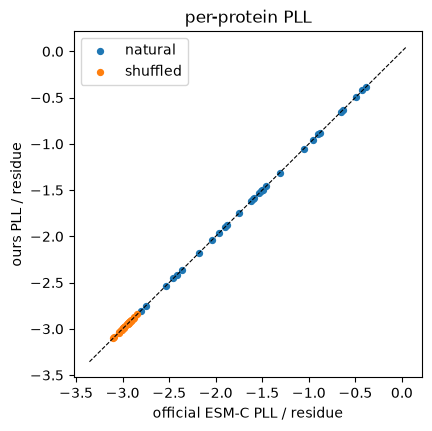

In [6]:
diffs = []
for (name, kind, m), lp in per_pos.items():
    if m == "ours":
        d = (lp - per_pos[(name, kind, "official")]).abs() if (name, kind, "official") in per_pos else None
        if d is not None:
            diffs.append(dict(name=name, kind=kind, max_abs_logp_diff=d.max().item(), mean_abs_logp_diff=d.mean().item()))
diffs = pd.DataFrame(diffs)
print(diffs[["max_abs_logp_diff", "mean_abs_logp_diff"]].describe().loc[["mean", "max"]].to_string())

w = res.pivot_table(index=["name", "kind"], columns="model", values="pll").reset_index()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for kind, c in [("natural", "C0"), ("shuffled", "C1")]:
    s = w[w.kind == kind]
    ax.scatter(s.official, s.ours, s=18, c=c, label=kind)
lim = [w[["official", "ours"]].min().min() - 0.1, 0.05]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="official ESM-C PLL / residue", ylabel="ours PLL / residue", title="per-protein PLL")
ax.legend(); plt.show()

## 2. Are the numbers good?

Expected: natural proteins have a pseudo-perplexity in the low single digits, with very conserved proteins near 1. Shuffled and random sequences sit near 20 (uniform). Recovery on natural proteins should be well above 1/20 = 5%. ESM-C 300M is reported to be roughly on par with ESM-2 650M, so the two columns should be close.

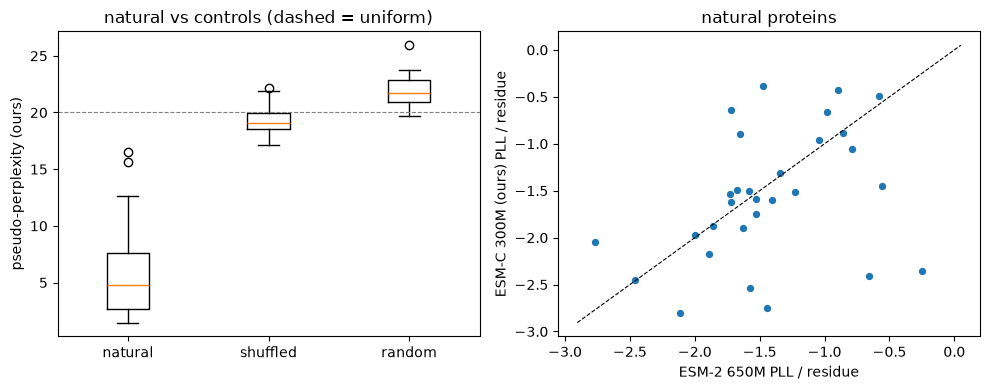

ppl                  recovery               
model            esm2_650m official   ours esm2_650m official  ours
name         L                                                     
BCHB_CHLTE   52       4.87     4.49   4.49      0.52     0.54  0.54
CUE1_YEAST   52       6.44     6.52   6.52      0.44     0.42  0.42
PITX2_HUMAN  52       4.35     1.47   1.47      0.58     0.90  0.90
YAIA_ECOLI   52       1.93    11.16  11.16      0.79     0.25  0.25
DN7A_SACS2   55       7.39     7.16   7.16      0.42     0.45  0.45
RFAH_ECOLI   55       4.61     4.90   4.90      0.55     0.49  0.49
SBI_STAAM    56       6.63     8.81   8.81      0.45     0.34  0.34
NKX31_HUMAN  61       5.57     1.89   1.89      0.49     0.79  0.79
PR40A_HUMAN  63       2.37     2.42   2.42      0.78     0.76  0.76
RCRO_LAMBD   63       5.58     5.04   5.04      0.51     0.52  0.52
RS15_GEOSE   63       2.67     1.93   1.93      0.63     0.79  0.79
DOCK1_MOUSE  66       5.09     6.70   6.70      0.56     0.42  0.42
PSAE_PICP2   68       5.23     2.45   2.45      0.49     0.76  0.76
ARGR_ECOLI   69       5.63     4.65   4.65      0.46     0.52  0.52
FKBP3_HUMAN  69      11.76    11.65  11.65      0.23     0.19  0.19
CBPA2_HUMAN  72       4.81    12.62  12.62      0.53     0.24  0.24
IF1_ECOLI    72       1.78     1.64   1.64      0.81     0.82  0.82
TAT_HV1BR    86      15.91     7.71   7.71      0.16     0.38  0.38
REV_HV1H2    116      1.28    10.58  10.58      0.91     0.26  0.26
RASH_HUMAN   189      2.45     1.53   1.53      0.71     0.86  0.86
B2L11_HUMAN  198      4.24    15.66  15.66      0.58     0.20  0.20
ESTA_BACSU   212      5.35     4.46   4.46      0.48     0.49  0.49
TPMT_HUMAN   245      3.43     4.53   4.53      0.64     0.52  0.52
TRPC_SACS2   248      3.83     3.72   3.72      0.54     0.53  0.53
CASP3_HUMAN  258      2.20     2.87   2.87      0.75     0.67  0.67
A4GRB6_PSEAI 266      4.08     4.92   4.92      0.55     0.50  0.50
OPSD_HUMAN   348      1.75     4.28   4.28      0.82     0.51  0.51
SERC_HUMAN   370      2.84     2.61   2.61      0.67     0.68  0.68
PAI1_HUMAN   402      4.59     5.74   5.74      0.52     0.47  0.47
NRAM_I33A0   453      8.28    16.53  16.53      0.36     0.13  0.13

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = ["natural", "shuffled", "random"]
o = res[res.model == "ours"]
axes[0].boxplot([o[o.kind == k].ppl for k in order], tick_labels=order)
axes[0].axhline(20, ls="--", c="gray", lw=0.8)
axes[0].set(ylabel="pseudo-perplexity (ours)", title="natural vs controls (dashed = uniform)")

nat = w[w.kind == "natural"]
axes[1].scatter(nat.esm2_650m, nat.ours, s=18)
lim = [min(nat.esm2_650m.min(), nat.ours.min()) - 0.1, 0.05]
axes[1].plot(lim, lim, "k--", lw=0.8)
axes[1].set(xlabel="ESM-2 650M PLL / residue", ylabel="ESM-C 300M (ours) PLL / residue",
            title="natural proteins")
plt.tight_layout(); plt.show()

table = (res[res.kind == "natural"]
         .pivot_table(index=["name", "L"], columns="model", values=["ppl", "recovery"])
         .round(2).sort_index(level="L"))
table

## 3. bf16 vs fp32

In [8]:
ours_bf16 = load_esmc("esmc_300m", device=DEV, dtype=torch.bfloat16)
bf = []
for p in proteins:
    if p["kind"] != "natural":
        continue
    lp, _ = masked_logprobs(lambda b: ours_bf16(b).logits, tok.encode(p["seq"]), MASK)
    ref = per_pos[(p["name"], "natural", "ours")]
    bf.append(dict(name=p["name"], pll_fp32=ref.mean().item(), pll_bf16=lp.mean().item(),
                   max_abs_logp_diff=(lp - ref).abs().max().item()))
bf = pd.DataFrame(bf)
bf["pll_diff"] = (bf.pll_bf16 - bf.pll_fp32).abs()
print(bf[["pll_diff", "max_abs_logp_diff"]].describe().loc[["mean", "max"]].to_string())
del ours_bf16; torch.cuda.empty_cache()

      pll_diff  max_abs_logp_diff
mean  0.003003           0.137988
max   0.013584           0.252228


## Verdict

In [9]:
med = res.groupby(["kind", "model"]).ppl.median()
checks = {
    "ours == official (max per-residue |dlogp| < 1e-4)": diffs.max_abs_logp_diff.max() < 1e-4,
    "ours == official (per-protein |dPLL| < 1e-5)": (w.ours - w.official).abs().max() < 1e-5,
    "natural median pPPL < 8": med["natural", "ours"] < 8,
    "shuffled median pPPL > 14": med["shuffled", "ours"] > 14,
    "random median pPPL > 14": med["random", "ours"] > 14,
    "every natural protein beats its own shuffle": (w[w.kind == "natural"].set_index("name").ours
                                                    > w[w.kind == "shuffled"].set_index("name").ours).all(),
    "natural recovery > 25%": res[(res.kind == "natural") & (res.model == "ours")].recovery.median() > 0.25,
    "within 1.5x of ESM-2 650M pPPL (median)": med["natural", "ours"] < 1.5 * med["natural", "esm2_650m"],
    "bf16 per-protein |dPLL| < 0.05": bf.pll_diff.max() < 0.05,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())

PASS ours == official (max per-residue |dlogp| < 1e-4)
PASS ours == official (per-protein |dPLL| < 1e-5)
PASS natural median pPPL < 8
PASS shuffled median pPPL > 14
PASS random median pPPL > 14
PASS every natural protein beats its own shuffle
PASS natural recovery > 25%
PASS within 1.5x of ESM-2 650M pPPL (median)
PASS bf16 per-protein |dPLL| < 0.05
